# 3.1

--- 3.1 DATASET DESCRIPTION ---

Files loaded successfully.

[Basic Statistics]
Total Repositories (M): 5
Time Range: 2010-04-06 to 2025-11-03
Total Data Points: 23047

[Metadata Insights]
Unique Languages: 5
Top Languages: JavaScript, C++, Python
Total Topics tagged across repos: 25

[Data Quality Check]
Potential Anomaly Warning: Repositories like ['tensorflow/tensorflow'] have very low variance in star counts (e.g., flat lines).


c:\Users\Ritama\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ritama\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


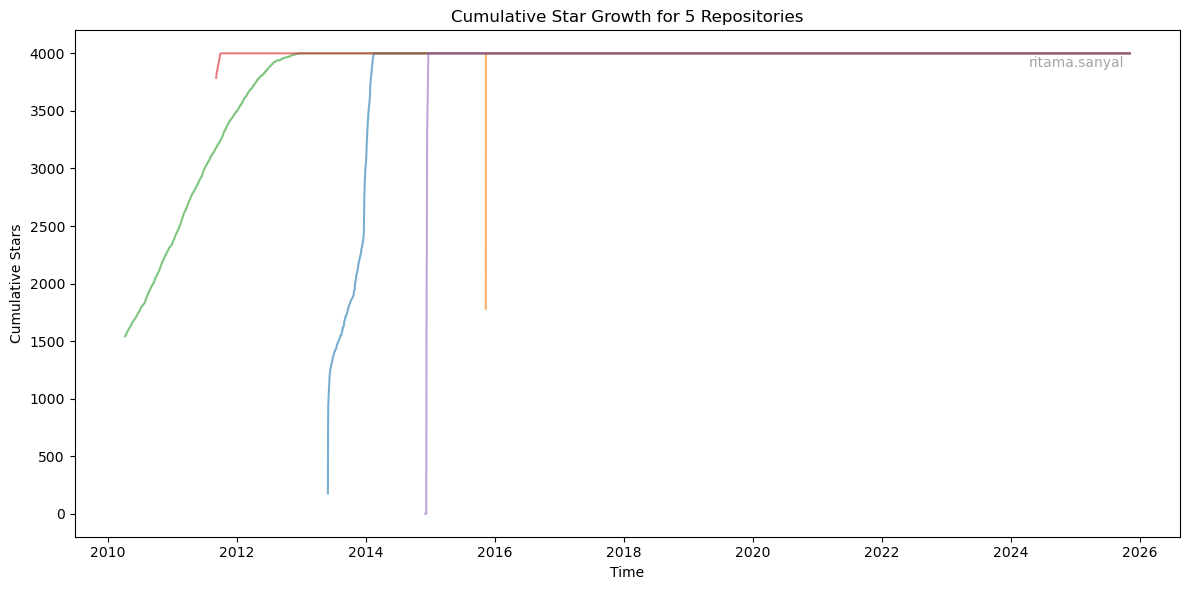

Visualization complete. Note any clusters or outliers in the plot above.


In [1]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 3.1 Dataset Description
# ==========================================

def describe_dataset():
    """
    Loads dataset files, prints summary statistics, analyzes metadata,
    and visualizes the overall dataset trends.
    """
    print("--- 3.1 DATASET DESCRIPTION ---\n")

    # 1. Load Data
    try:
        df = pd.read_csv('stars_data.csv')
        with open('repo_metadata.json', 'r') as f:
            metadata = json.load(f)
        
        # Convert timestamp to datetime
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        
        print("Files loaded successfully.")
    except FileNotFoundError as e:
        print(f"Error loading files: {e}")
        return

    # 2. Basic Statistics
    # Total number of repositories (M)
    unique_repos = df['repository_id'].unique()
    M = len(unique_repos)
    
    # Time Range
    start_date = df['timestamp'].min()
    end_date = df['timestamp'].max()
    
    print(f"\n[Basic Statistics]")
    print(f"Total Repositories (M): {M}")
    print(f"Time Range: {start_date.date()} to {end_date.date()}")
    print(f"Total Data Points: {len(df)}")

    # 3. Metadata Analysis (Languages & Topics)
    languages = []
    topics_count = 0
    
    for repo_id, info in metadata.items():
        if info.get('language'):
            languages.append(info['language'])
        topics_count += len(info.get('topics', []))

    language_counts = pd.Series(languages).value_counts()

    print(f"\n[Metadata Insights]")
    print(f"Unique Languages: {len(language_counts)}")
    print(f"Top Languages: {', '.join(language_counts.head(3).index.tolist())}")
    print(f"Total Topics tagged across repos: {topics_count}")

    # 4. Data Quality Check (Looking for anomalies like the 4000 flatline)
    # We check the variance of stars for a sample to see if it's flat
    print(f"\n[Data Quality Check]")
    anomalies = []
    for repo in unique_repos[:3]: # Check first few
        repo_df = df[df['repository_id'] == repo]
        if repo_df['stars'].nunique() < 5 and len(repo_df) > 100:
             anomalies.append(repo)
    
    if anomalies: 
        print(f"Potential Anomaly Warning: Repositories like {anomalies} have very low variance in star counts (e.g., flat lines).")
    else:
        print("No immediate flat-line anomalies detected in sample.")

    # 5. Visualization: Global Growth Trends
    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df, x='timestamp', y='stars', hue='repository_id', legend=False, alpha=0.6)
    
    # Add your specific text tag as required by Submission Instructions
    plt.text(
        0.95, 0.95, 
        "ritama.sanyal",  # REPLACE with your actual email ritama.sanyal
        ha='right', va='top', 
        transform=plt.gca().transAxes, 
        fontsize=10, color='gray', alpha=0.7
    )
    
    plt.title(f"Cumulative Star Growth for {M} Repositories")
    plt.xlabel("Time")
    plt.ylabel("Cumulative Stars")
    plt.tight_layout()
    plt.show()
    
    print("Visualization complete. Note any clusters or outliers in the plot above.")

# Execute the function
describe_dataset()

# 3.2.1

Processing pallets/flask...
Processing facebook/react...


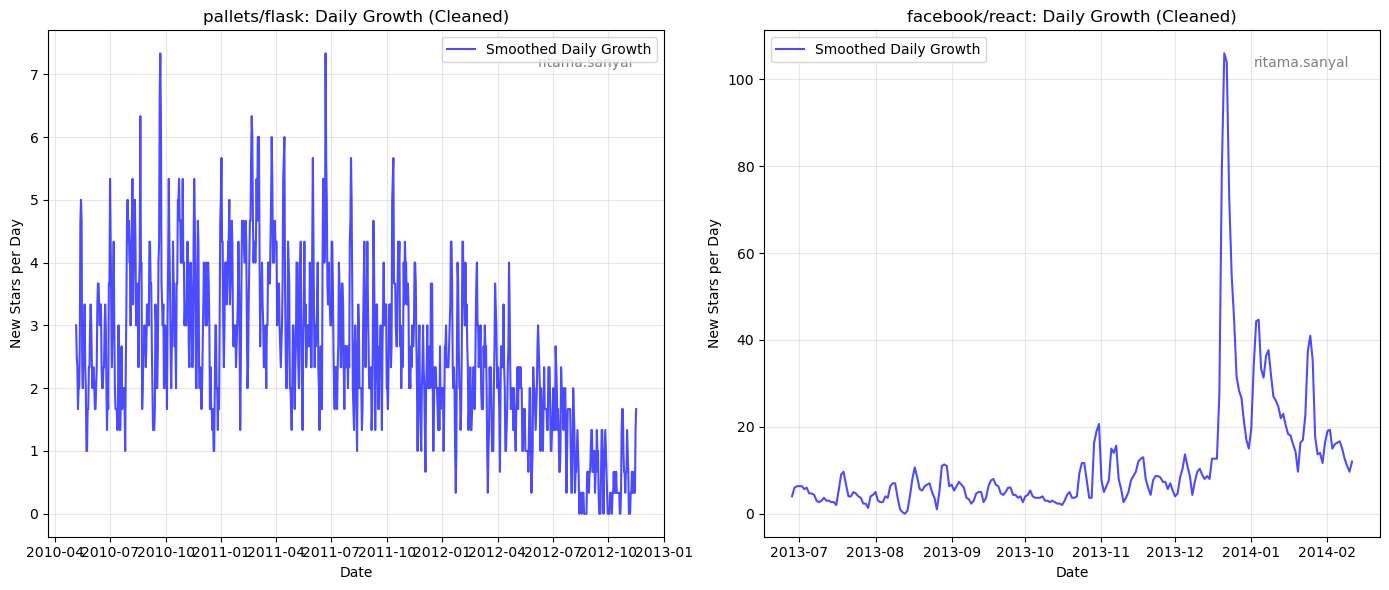

Advanced preprocessing complete. 'processed_data' is updated.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 3.2.1 ADVANCED PREPROCESSING
# ==========================================

def preprocess_repo_v2(df, repo_id, cutoff_threshold=3990, trim_start=30, smooth_window=3):
    """
    Advanced cleaning:
    1. Truncates '4000 ceiling' artifact.
    2. Trims the first N 'viral' days.
    3. Smooths daily noise using a rolling mean.
    """
    print(f"Processing {repo_id}...")
    
    # 1. Filter & Sort
    repo_data = df[df['repository_id'] == repo_id].sort_values('timestamp').set_index('timestamp')
    
    # 2. Artifact Removal (4000 ceiling)
    artifact_start = repo_data[repo_data['stars'] >= cutoff_threshold].index.min()
    if pd.notna(artifact_start):
        repo_data = repo_data[repo_data.index <= artifact_start]

    # 3. Resample to Daily (Handle missing days)
    repo_daily = repo_data['stars'].resample('D').max().interpolate(method='linear')
    
    # 4. Calculate Incremental (Daily Changes)
    incremental = repo_daily.diff().fillna(0)
    
    # 5. TRIM VIRAL PHASE (New!)
    # Remove the first 'trim_start' days where behavior is erratic
    if len(incremental) > trim_start:
        incremental = incremental.iloc[trim_start:]
        repo_daily = repo_daily.iloc[trim_start:]
    
    # 6. SMOOTHING (New!)
    # Apply rolling mean to reduce spike noise
    # We use 'min_periods=1' to avoid NaNs at the start
    incremental_smooth = incremental.rolling(window=smooth_window, min_periods=1).mean()
    
    # Reconstruct 'Smoothed Cumulative' based on the smoothed incremental changes
    # This ensures the math stays consistent
    cumulative_smooth = repo_daily.iloc[0] + incremental_smooth.cumsum() - incremental_smooth.iloc[0]

    return pd.DataFrame({
        'cumulative': cumulative_smooth,
        'incremental': incremental_smooth
    })

def create_splits(df, split_ratio=0.8):
    train_size = int(len(df) * split_ratio)
    return df.iloc[:train_size], df.iloc[train_size:]

# --- EXECUTE & COMPARE ---
df_raw = pd.read_csv('stars_data.csv')
df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'])

target_repos = ['pallets/flask', 'facebook/react']
processed_data = {}

plt.figure(figsize=(14, 6))

for i, repo in enumerate(target_repos):
    # Apply V2 Preprocessing
    # We trim first 30 days and apply a 3-day smoothing window
    clean_df = preprocess_repo_v2(df_raw, repo, trim_start=30, smooth_window=3)
    
    # Store for modeling
    train_df, test_df = create_splits(clean_df)
    processed_data[repo] = {'train': train_df, 'test': test_df}
    
    # Plot Incremental (Daily Changes) to show smoothness
    plt.subplot(1, 2, i+1)
    plt.plot(clean_df.index, clean_df['incremental'], label='Smoothed Daily Growth', color='blue', alpha=0.7)
    plt.title(f"{repo}: Daily Growth (Cleaned)")
    plt.xlabel("Date")
    plt.ylabel("New Stars per Day")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.text(0.95, 0.95, "ritama.sanyal", ha='right', va='top', transform=plt.gca().transAxes, color='gray')

plt.tight_layout()
plt.show()

print("Advanced preprocessing complete. 'processed_data' is updated.")

In [3]:
def find_best_candidates(df, threshold=3990):
    candidates = []
    
    for repo in df['repository_id'].unique():
        # Extract repo data
        repo_df = df[df['repository_id'] == repo].sort_values('timestamp')
        repo_df = repo_df.set_index('timestamp')
        
        # Find cutoff
        artifact_start = repo_df[repo_df['stars'] >= threshold].index.min()
        
        if pd.notna(artifact_start):
            valid_data = repo_df[repo_df.index <= artifact_start]
        else:
            valid_data = repo_df # No artifact found, use full data!
            
        # Calculate duration
        if len(valid_data) > 0:
            duration = (valid_data.index.max() - valid_data.index.min()).days
            count = len(valid_data)
            candidates.append((repo, count, duration))
            
    # Sort by count of valid data points (descending)
    candidates.sort(key=lambda x: x[1], reverse=True)
    
    print(f"{'Repository ID':<30} | {'Points':<10} | {'Duration (Days)':<15}")
    print("-" * 60)
    for c in candidates[:5]:
        print(f"{c[0]:<30} | {c[1]:<10} | {c[2]:<15}")

# Run search on your loaded df_raw
find_best_candidates(df_raw)

Repository ID                  | Points     | Duration (Days)
------------------------------------------------------------
pallets/flask                  | 956        | 955            
facebook/react                 | 259        | 258            
torvalds/linux                 | 24         | 23             
golang/go                      | 19         | 18             
tensorflow/tensorflow          | 2          | 1              


# 3.2.2

## 1. Data Preparation Strategy

### **For Classical Models (ARMA)**

- **Stationarity Requirement:**  
  The raw *Cumulative Stars* data is non-stationary due to its constant upward trend.  
  ARMA models assume stationarity.

- **Differencing:**  
  To enforce stationarity, we converted cumulative values into incremental values:  
  \[
  y_t' = y_t - y_{t-1}
  \]  
  This removes the trend and stabilizes the mean, making the series suitable for ARMA modeling.

---

### **For Deep Learning Models (RNN / CNN)**

- **Scaling:**  
  - Applied **MinMaxScaler** to the incremental data.  
  - The scaler was **fitted only on the training set** to prevent data leakage.  
  - Neural networks require small input ranges (e.g., 0–1) for stable gradient descent and faster convergence.

- **Sliding Window (Sequencing):**  
  Transformed the time series into a supervised learning task using a sliding window.  
  For a lookback window \(k = 14\):
  - **Input \(X\):** last 14 days of *new stars*  
  - **Target \(y\):** next day’s *new stars*

---

## 2. Loss Function Justification

### **Choice: Mean Squared Error (MSE)**

### **Why MSE?**
- MSE penalizes **larger errors more strongly** than MAE.  
- In time-series forecasting, large deviations can distort the reconstructed cumulative trajectory.  
- Using MSE encourages the model to stay near the “average path,” reducing volatility and improving long-term forecast stability.



--- Modeling: pallets/flask ---

  [Training RNN]
    Epoch 1/100 | Loss: 0.047183
    Epoch 10/100 | Loss: 0.011425
    Epoch 20/100 | Loss: 0.008341
    Epoch 30/100 | Loss: 0.008523
    Epoch 40/100 | Loss: 0.008504
    Epoch 50/100 | Loss: 0.008524
    Epoch 60/100 | Loss: 0.008172
    Epoch 70/100 | Loss: 0.008201
    Epoch 80/100 | Loss: 0.008345
    Epoch 90/100 | Loss: 0.008436
    Epoch 100/100 | Loss: 0.008193

  [Training CNN]
    Epoch 1/100 | Loss: 0.043113
    Epoch 10/100 | Loss: 0.010811
    Epoch 20/100 | Loss: 0.009259
    Epoch 30/100 | Loss: 0.009016
    Epoch 40/100 | Loss: 0.008748
    Epoch 50/100 | Loss: 0.008480
    Epoch 60/100 | Loss: 0.008420
    Epoch 70/100 | Loss: 0.008030
    Epoch 80/100 | Loss: 0.008045
    Epoch 90/100 | Loss: 0.007978
    Epoch 100/100 | Loss: 0.008003


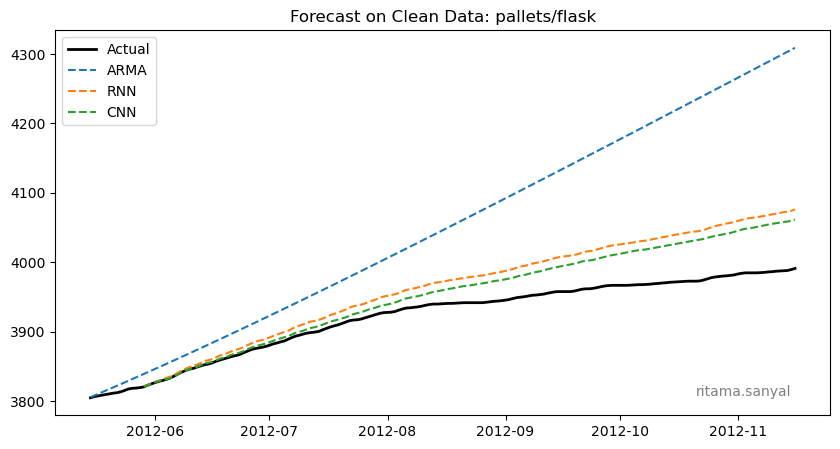


pallets/flask RMSE Results:
  ARMA: 167.43
  RNN:  46.32
  CNN:  35.98

--- Modeling: facebook/react ---

  [Training RNN]
    Epoch 1/100 | Loss: 0.029010
    Epoch 10/100 | Loss: 0.011245
    Epoch 20/100 | Loss: 0.008347
    Epoch 30/100 | Loss: 0.004485
    Epoch 40/100 | Loss: 0.003628
    Epoch 50/100 | Loss: 0.003165
    Epoch 60/100 | Loss: 0.002416
    Epoch 70/100 | Loss: 0.002227
    Epoch 80/100 | Loss: 0.001794
    Epoch 90/100 | Loss: 0.001662
    Epoch 100/100 | Loss: 0.001618

  [Training CNN]
    Epoch 1/100 | Loss: 0.024667
    Epoch 10/100 | Loss: 0.011230
    Epoch 20/100 | Loss: 0.008025
    Epoch 30/100 | Loss: 0.005785
    Epoch 40/100 | Loss: 0.006513
    Epoch 50/100 | Loss: 0.004275
    Epoch 60/100 | Loss: 0.003623
    Epoch 70/100 | Loss: 0.003156
    Epoch 80/100 | Loss: 0.002952
    Epoch 90/100 | Loss: 0.002452
    Epoch 100/100 | Loss: 0.002597


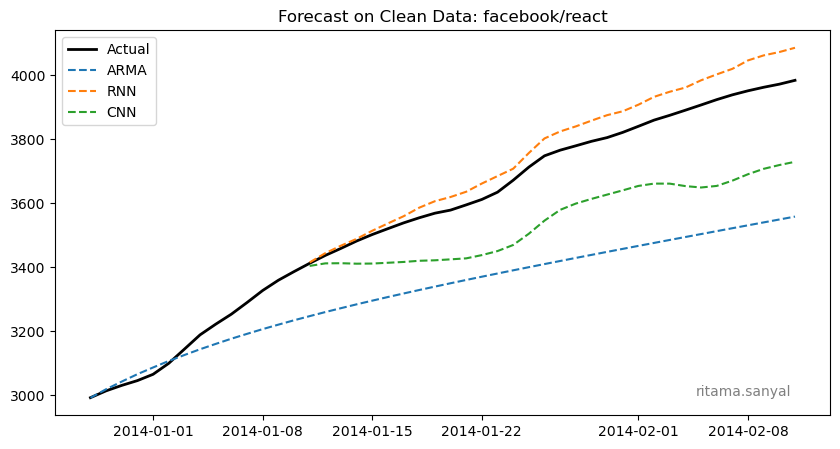


facebook/react RMSE Results:
  ARMA: 323.18
  RNN:  60.47
  CNN:  188.49


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings

# Clean output
warnings.filterwarnings("ignore")

# ==========================================
# CONFIGURATION
# ==========================================
CONFIG = {
    'lookback': 14,
    'batch_size': 16,
    'epochs': 100,
    'lr': 0.001,
}

# Helper
def reconstruct_cumulative(base_value, incremental_preds):
    return base_value + np.cumsum(incremental_preds)

# ==========================================
# 1. CLASSICAL FORECASTER (Robust)
# ==========================================
class ClassicalForecaster:
    def __init__(self, order=(5,0,5)):
        self.primary_order = order
        self.fallback_orders = [(2, 0, 2), (1, 0, 1), (1, 0, 0)] 
        self.model_fit = None

    def fit(self, train_data):
        # Ensure clean
        clean_data = train_data.fillna(0)
        
        # Try Primary
        try:
            model = ARIMA(clean_data, order=self.primary_order)
            self.model_fit = model.fit()
            return
        except:
            pass

        # Try Fallbacks
        for order in self.fallback_orders:
            try:
                model = ARIMA(clean_data, order=order)
                self.model_fit = model.fit()
                print(f"  -> Fallback to ARMA{order} successful.")
                return
            except:
                continue
        print("  -> All ARMA attempts failed.")

    def predict(self, steps):
        if self.model_fit:
            return self.model_fit.forecast(steps=steps)
        return np.zeros(steps)

# ==========================================
# 2. DEEP LEARNING CLASSES
# ==========================================
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

class SmallRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32):
        super(SmallRNN, self).__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class SmallCNN(nn.Module):
    def __init__(self, lookback, filters=32):
        super(SmallCNN, self).__init__()
        self.conv1 = nn.Conv1d(1, filters, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(2)
        flat_size = filters * (lookback // 2)
        self.fc = nn.Linear(flat_size, 1)
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        x = self.pool(self.relu(self.conv1(x)))
        x = x.reshape(x.size(0), -1) 
        return self.fc(x)

# ==========================================
# 3. TRAINING HELPERS (Updated with Print)
# ==========================================
def train_dl(model, train_data, model_name="Model"):
    print(f"\n  [Training {model_name}]")
    scaler = MinMaxScaler()
    data_clean = train_data.fillna(0).values.reshape(-1, 1)
    train_scaled = scaler.fit_transform(data_clean)
    
    # Create Sequences
    X, y = [], []
    for i in range(len(train_scaled) - CONFIG['lookback']):
        X.append(train_scaled[i:i+CONFIG['lookback']])
        y.append(train_scaled[i+CONFIG['lookback']])
    
    X, y = np.array(X), np.array(y)
    if len(X) == 0: return model, scaler

    loader = DataLoader(TimeSeriesDataset(X, y), batch_size=CONFIG['batch_size'], shuffle=True)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['lr'])
    
    model.train()
    loss_history = []
    
    for epoch in range(CONFIG['epochs']):
        epoch_loss = 0
        count = 0
        for X_b, y_b in loader:
            optimizer.zero_grad()
            loss = criterion(model(X_b), y_b)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            count += 1
        
        # Calculate average loss for the epoch
        avg_loss = epoch_loss / count
        loss_history.append(avg_loss)
        
        # Print every 10 epochs (and the first/last)
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"    Epoch {epoch+1}/{CONFIG['epochs']} | Loss: {avg_loss:.6f}")
            
    return model, scaler

def predict_dl(model, scaler, test_data):
    model.eval()
    data_clean = test_data.fillna(0).values.reshape(-1, 1)
    test_scaled = scaler.transform(data_clean)
    preds = []
    
    for i in range(len(test_scaled) - CONFIG['lookback']):
        seq = test_scaled[i:i+CONFIG['lookback']]
        seq_tensor = torch.tensor(seq, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            preds.append(model(seq_tensor).item())
            
    return scaler.inverse_transform(np.array(preds).reshape(-1, 1))

# ==========================================
# EXECUTION
# ==========================================
for repo, data in processed_data.items():
    print(f"\n{'='*40}\n--- Modeling: {repo} ---\n{'='*40}")
    train, test = data['train'], data['test']
    
    # 1. ARMA
    arma = ClassicalForecaster()
    arma.fit(train['incremental'])
    arma_pred = arma.predict(len(test))
    
    # 2. DL Models (Now prints loss!)
    rnn, rnn_sc = train_dl(SmallRNN(), train['incremental'], model_name="RNN")
    cnn, cnn_sc = train_dl(SmallCNN(CONFIG['lookback']), train['incremental'], model_name="CNN")
    
    rnn_pred = predict_dl(rnn, rnn_sc, test['incremental'])
    cnn_pred = predict_dl(cnn, cnn_sc, test['incremental'])
    
    # 3. Reconstruction
    valid_idx = test.index[CONFIG['lookback']:]
    base = test['cumulative'].iloc[CONFIG['lookback']-1]
    
    rnn_cum = reconstruct_cumulative(base, rnn_pred.flatten())
    cnn_cum = reconstruct_cumulative(base, cnn_pred.flatten())
    arma_cum = reconstruct_cumulative(train['cumulative'].iloc[-1], arma_pred)
    
    # 4. Plot
    plt.figure(figsize=(10, 5))
    plt.plot(test.index, test['cumulative'], label='Actual', color='k', lw=2)
    plt.plot(test.index, arma_cum, '--', label='ARMA')
    plt.plot(valid_idx, rnn_cum, '--', label='RNN')
    plt.plot(valid_idx, cnn_cum, '--', label='CNN')
    plt.title(f"Forecast on Clean Data: {repo}")
    plt.legend()
    plt.text(0.95, 0.05, "ritama.sanyal", ha='right', transform=plt.gca().transAxes, color='gray')
    plt.show()
    
    # 5. RMSE
    true = test['cumulative'].loc[valid_idx]
    arma_sl = pd.Series(arma_cum, index=test.index).loc[valid_idx]
    print(f"\n{repo} RMSE Results:")
    print(f"  ARMA: {np.sqrt(mean_squared_error(true, arma_sl)):.2f}")
    print(f"  RNN:  {np.sqrt(mean_squared_error(true, rnn_cum)):.2f}")
    print(f"  CNN:  {np.sqrt(mean_squared_error(true, cnn_cum)):.2f}")

# 3.2.3


--- Analyzing Stability: pallets/flask ---

--- Analyzing Stability: facebook/react ---


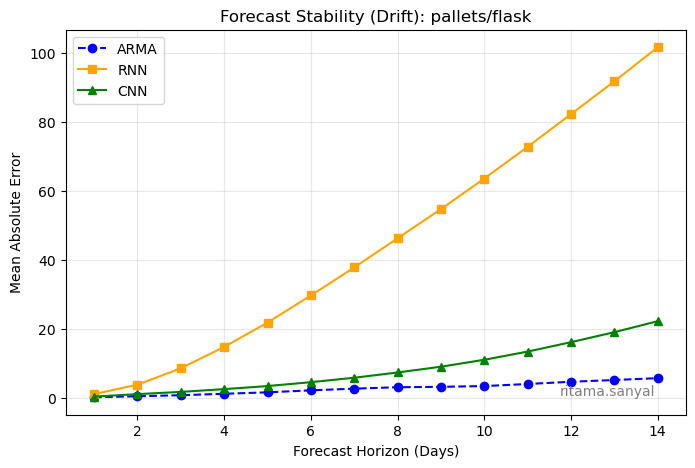

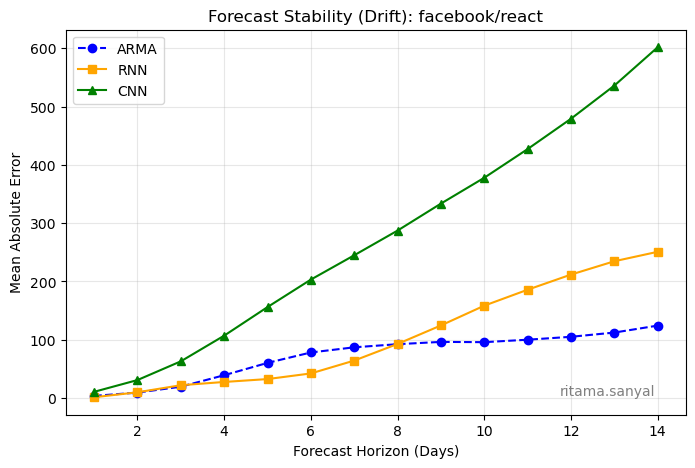

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from statsmodels.tsa.arima.model import ARIMA

# ==========================================
# 3.2.3 MULTI-STEP EVALUATION (UPDATED)
# ==========================================

def evaluate_horizon_all(processed_data, rnn_model, rnn_scaler, cnn_model, cnn_scaler, max_horizon=14, stride=10):
    """
    Evaluates stability for RNN, CNN, AND ARMA.
    """
    results = {}
    
    for repo, data in processed_data.items():
        print(f"\n--- Analyzing Stability: {repo} ---")
        test = data['test']
        train = data['train']
        
        # Prepare Data Arrays
        inc_data = test['incremental'].values
        cum_data = test['cumulative'].values
        
        # Initialize Error Trackers
        errors = {
            'ARMA': {h: [] for h in range(1, max_horizon + 1)},
            'RNN': {h: [] for h in range(1, max_horizon + 1)},
            'CNN': {h: [] for h in range(1, max_horizon + 1)}
        }
        
        # Define Rolling Window Bounds
        start_idx = CONFIG['lookback']
        stop_idx = len(test) - max_horizon
        
        # --- ROLLING LOOP ---
        for t in range(start_idx, stop_idx, stride):
            if t % 20 == 0: print(f"  -> Step {t}/{stop_idx}...")

            # ===========================
            # 1. ARMA FORECAST (The Logic We Added)
            # ===========================
            # We combine Train + Test_History_Up_To_T to fit the model
            history = np.concatenate([train['incremental'].values, inc_data[:t]])
            # Fit simple model on history (Use (1,0,1) for speed in loop, or (5,0,5) if patient)
            try:
                arma_model = ARIMA(history, order=(5,0,5)).fit()
                arma_pred_inc = arma_model.forecast(steps=max_horizon)
            except:
                # Fallback if convergence fails
                arma_pred_inc = np.zeros(max_horizon)
            
            # Reconstruct ARMA Cumulative
            arma_base = cum_data[t-1]
            arma_pred_cum = arma_base + np.cumsum(arma_pred_inc)

            # ===========================
            # 2. DL MODELS FORECAST
            # ===========================
            # Prepare Input Tensor
            raw_seq = inc_data[t-CONFIG['lookback']:t]
            scaled_seq = rnn_scaler.transform(raw_seq.reshape(-1, 1)).flatten()
            
            # RNN Loop
            curr_seq_rnn = scaled_seq.copy()
            rnn_pred_inc = []
            for _ in range(max_horizon):
                in_tensor = torch.tensor(curr_seq_rnn, dtype=torch.float32).reshape(1, -1, 1)
                with torch.no_grad(): val = rnn_model(in_tensor).item()
                rnn_pred_inc.append(val)
                curr_seq_rnn = np.append(curr_seq_rnn[1:], val)
            
            # CNN Loop
            curr_seq_cnn = scaled_seq.copy()
            cnn_pred_inc = []
            for _ in range(max_horizon):
                in_tensor = torch.tensor(curr_seq_cnn, dtype=torch.float32).reshape(1, -1, 1)
                with torch.no_grad(): val = cnn_model(in_tensor).item()
                cnn_pred_inc.append(val)
                curr_seq_cnn = np.append(curr_seq_cnn[1:], val)

            # Inverse Scale & Reconstruct
            rnn_pred_inc = rnn_scaler.inverse_transform(np.array(rnn_pred_inc).reshape(-1,1)).flatten()
            cnn_pred_inc = cnn_scaler.inverse_transform(np.array(cnn_pred_inc).reshape(-1,1)).flatten()
            
            rnn_pred_cum = cum_data[t-1] + np.cumsum(rnn_pred_inc)
            cnn_pred_cum = cum_data[t-1] + np.cumsum(cnn_pred_inc)
            
            # ===========================
            # 3. CALCULATE ERRORS
            # ===========================
            true_cum = cum_data[t : t+max_horizon]
            
            for h in range(max_horizon):
                errors['ARMA'][h+1].append(abs(arma_pred_cum[h] - true_cum[h]))
                errors['RNN'][h+1].append(abs(rnn_pred_cum[h] - true_cum[h]))
                errors['CNN'][h+1].append(abs(cnn_pred_cum[h] - true_cum[h]))

        # Aggregate
        results[repo] = {
            model: {h: np.mean(errs) for h, errs in h_errs.items()}
            for model, h_errs in errors.items()
        }
        
    return results

# --- EXECUTE ---
# Note: Assumes 'processed_data', 'rnn', 'cnn', etc. exist from previous block
# If they don't, re-run the 3.2.2 block first.

horizon_data = evaluate_horizon_all(processed_data, rnn, rnn_sc, cnn, cnn_sc, max_horizon=14)

# --- PLOT ---
for repo, models in horizon_data.items():
    plt.figure(figsize=(8, 5))
    plt.plot(list(models['ARMA'].keys()), list(models['ARMA'].values()), 'o--', label='ARMA', color='blue')
    plt.plot(list(models['RNN'].keys()), list(models['RNN'].values()), 's-', label='RNN', color='orange')
    plt.plot(list(models['CNN'].keys()), list(models['CNN'].values()), '^-', label='CNN', color='green')
    
    plt.title(f"Forecast Stability (Drift): {repo}")
    plt.xlabel("Forecast Horizon (Days)")
    plt.ylabel("Mean Absolute Error")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.text(0.95, 0.05, "ritama.sanyal", ha='right', transform=plt.gca().transAxes, color='gray')
    plt.show()

https://gemini.google.com/share/89a809657111